In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import nltk

nltk.download("punkt")
nltk.download("punkt_tab")

[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\Linzz\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to
[nltk_data]     C:\Users\Linzz\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


True

In [ ]:
#extract dataset
import pandas as pd

#load dataset
data = pd.read_csv('scrape_kompas_clean.csv')

#menampilkan 10 data pertama
print(data.head(10))

#melihat 10 data terakhir
print(data.tail(10))

#informasi dataset
print(data.info())

#ukuran dataset
print(data.shape)

#melihat nama kolom
print(data.columns)

                                                link                 date  \
0  https://entertainment.kompas.com/read/2026/07/...  2026-07-30 09:26:57   
1  https://www.kompas.com/hype/read/2026/08/04/16...  2026-08-04 16:51:09   
2  https://entertainment.kompas.com/read/2026/07/...  2026-07-14 12:05:38   
3  https://www.kompas.com/hype/read/2026/07/28/19...  2026-07-28 19:42:53   
4  https://www.kompas.com/hype/read/2026/08/04/11...  2026-08-04 11:52:54   
5  https://tekno.kompas.com/read/2026/07/04/10320...  2026-07-15 05:59:42   
6  https://entertainment.kompas.com/read/2026/07/...  2026-07-21 08:53:09   
7  https://www.kompas.com/hype/read/2026/08/05/09...  2026-08-05 09:04:16   
8  https://www.kompas.com/hype/read/2026/08/08/10...  2026-08-08 10:23:06   
9  https://nasional.kompas.com/read/2026/07/29/19...  2026-07-29 19:33:22   

                                               title  \
0      Deretan Aktor yang Pernah Perankan Spider-Man   
1  Aktor Ryotaro Shimizu Ditemukan Menin

In [16]:
#extract dataset
import pandas as pd

#load dataset
data = pd.read_csv('scrape_kompas_clean.csv')

#jumlah dokumen
jumlah_dokumen = len(data)
print("Jumlah dokumen:", jumlah_dokumen)

#memilih kolom teks
text_column = "title"
texts = data[text_column]
print("Teks dari kolom '{}':".format(text_column))

#melihat contoh teks
for text in texts.head(10):
    print(text)
    print("-" * 80)



Jumlah dokumen: 8926
Teks dari kolom 'title':
Deretan Aktor yang Pernah Perankan Spider-Man
--------------------------------------------------------------------------------
Aktor Ryotaro Shimizu Ditemukan Meninggal Dunia di Kediamannya
--------------------------------------------------------------------------------
Aktor Marvelous Mrs. Maisel, Josh Grisetti Meninggal Dunia
--------------------------------------------------------------------------------
Aktor Bittersweet Destiny, Wang Kai Ditemukan Meninggal Dunia di Rumahnya
--------------------------------------------------------------------------------
Aktor Thailand, Jorjay Phumhirun Mendadak Meninggal di Usia 20 Tahun
--------------------------------------------------------------------------------
Kalah Saing dengan AI, Aktor China Jualan Sayur karena Sepi "Job"
--------------------------------------------------------------------------------
Ayah Nicholas Tse dan Aktor Hong Kong, Patrick Tse Meninggal Dunia
------------------------

In [7]:
#memeriksa missing values
print (data.isnull().sum())

#menghitung missing values pada kolom teks
missing_values = data[text_column].isnull().sum()
print("Jumlah missing values pada kolom '{}': {}".format(text_column, missing_values))

#menghapus data kosong
data = data.dropna(subset=[text_column])
print("Jumlah missing values setelah dihapus:", data[text_column].isnull().sum())


link        0
date        0
title       0
content     0
keywords    3
category    0
dtype: int64
Jumlah missing values pada kolom 'title': 0
Jumlah missing values setelah dihapus: 0


In [8]:
#memeriksa duplikasi
data.duplicated().sum()
print("Jumlah data duplikasi:", data.duplicated().sum())

#memeriksa duplikasi khusus teks
data[text_column].duplicated().sum()
print("Jumlah data duplikasi khusus teks '{}': {}".format(text_column, data[text_column].duplicated().sum()))

#menghapus data duplikasi
data = data.drop_duplicates(subset=[text_column])
print("Jumlah data setelah menghapus duplikasi:", len(data))


Jumlah data duplikasi: 0
Jumlah data duplikasi khusus teks 'title': 7
Jumlah data setelah menghapus duplikasi: 8919


In [9]:
#menghitung jumlah karakter
data["jumlah_karakter"] = data[text_column].astype(str).apply(len)
print (data[[text_column, "jumlah_karakter"]].head())

#menghitung jumlah kata
data["jumlah_kata"] = data[text_column].astype(str).apply(
    lambda x: len(x.split())
)
print(data[[text_column, "jumlah_kata"]].head())

#statistik jumlah kata
print(data["jumlah_kata"].describe())

                                               title  jumlah_karakter
0      Deretan Aktor yang Pernah Perankan Spider-Man               45
1  Aktor Ryotaro Shimizu Ditemukan Meninggal Duni...               62
2  Aktor Marvelous Mrs. Maisel, Josh Grisetti Men...               58
3  Aktor Bittersweet Destiny, Wang Kai Ditemukan ...               73
4  Aktor Thailand, Jorjay Phumhirun Mendadak Meni...               68
                                               title  jumlah_kata
0      Deretan Aktor yang Pernah Perankan Spider-Man            6
1  Aktor Ryotaro Shimizu Ditemukan Meninggal Duni...            8
2  Aktor Marvelous Mrs. Maisel, Josh Grisetti Men...            8
3  Aktor Bittersweet Destiny, Wang Kai Ditemukan ...           10
4  Aktor Thailand, Jorjay Phumhirun Mendadak Meni...           10
count    8919.000000
mean       11.619800
std         2.212569
min         3.000000
25%        10.000000
50%        12.000000
75%        13.000000
max        23.000000
Name: jumlah_kat

In [19]:
#menghitung jumlah kalimat
from nltk.tokenize import sent_tokenize

text = "Saya belajar NLP. NLP sangat menarik."
sentences = sent_tokenize(text)
print(sentences)

#menghitung jumlah kalimat dalam dataset
data["jumlah_kalimat"] = data[text_column].astype(str).apply(
    lambda x: len(sent_tokenize(x))
)
print(data[[text_column, "jumlah_kalimat"]].head())


['Saya belajar NLP.', 'NLP sangat menarik.']
                                               title  jumlah_kalimat
0      Deretan Aktor yang Pernah Perankan Spider-Man               1
1  Aktor Ryotaro Shimizu Ditemukan Meninggal Duni...               1
2  Aktor Marvelous Mrs. Maisel, Josh Grisetti Men...               1
3  Aktor Bittersweet Destiny, Wang Kai Ditemukan ...               1
4  Aktor Thailand, Jorjay Phumhirun Mendadak Meni...               1


In [11]:
#melihat statistik corpus
print("Jumlah dokumen :", len(data))
print("Jumlah kata    :", data["jumlah_kata"].sum())
print("Jumlah kalimat :", data["jumlah_kalimat"].sum())
print("Jumlah karakter:", data["jumlah_karakter"].sum())

Jumlah dokumen : 8919
Jumlah kata    : 103637
Jumlah kalimat : 9068
Jumlah karakter: 685897


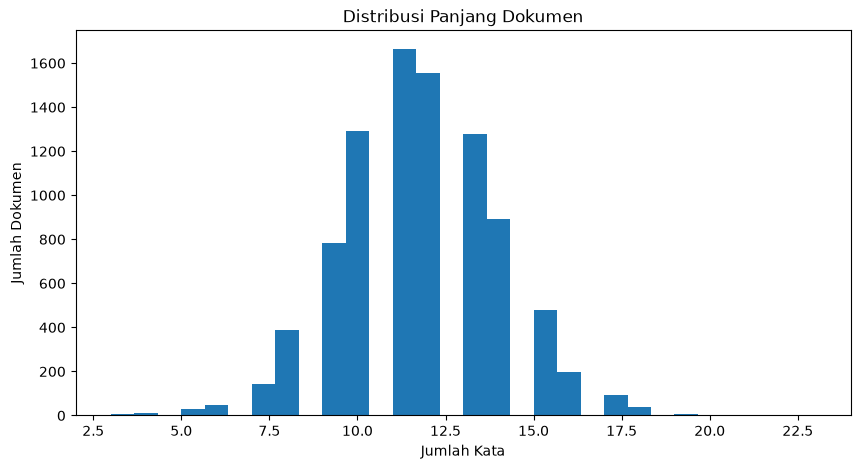

In [12]:
#visualisasi distribusi panjang dokumen
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(data["jumlah_kata"], bins=30)

plt.xlabel("Jumlah Kata")
plt.ylabel("Jumlah Dokumen")
plt.title("Distribusi Panjang Dokumen")

plt.show()

In [13]:
#jika dataset memiliki label
import matplotlib.pyplot as plt

# 1. Cek kolom apa saja yang ada
print("Kolom yang tersedia di dataset:")
print(data.columns.tolist())

# 2. Cek apakah ada kolom 'label'
if 'label' in data.columns:
    print("\n=== Jumlah Data per Label ===")
    print(data["label"].value_counts())
    
    # Visualisasi — persis seperti perintah dosen
    data["label"].value_counts().plot(kind="bar")
    plt.xlabel("Label")
    plt.ylabel("Jumlah Data")
    plt.title("Distribusi Label")
    plt.show()
else:
    print("\n✅ Pemeriksaan selesai")
    print("⚠️ Dataset TIDAK memiliki kolom 'label'")
    print("Artinya: data ini belum diberi kategori/golongan")

Kolom yang tersedia di dataset:
['link', 'date', 'title', 'content', 'keywords', 'category', 'jumlah_karakter', 'jumlah_kata', 'jumlah_kalimat']

✅ Pemeriksaan selesai
⚠️ Dataset TIDAK memiliki kolom 'label'
Artinya: data ini belum diberi kategori/golongan
